##ICA converted from FLUX pipeline

# Using ICA to reduce artefacts

This section will show how to use an independent component analysis (ICA) approach to suppress ocular and cardiac artefacts. This will be done by first performing an ICA decomposition of the data after which the components reflecting the artefacts are identified manually. As a last step the artefact components are 'projected out'.

## Preparation

Import the relevant Python modules:

In [2]:
import os
import gc
import numpy as np
import matplotlib.pyplot as plt

import mne
from mne.preprocessing import ICA

In [3]:
# Define your derivatives folder path
deriv_root = r'C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives'

# Project parameters
subject = 'CA103'
session = '1'
task = 'dur'
input_suffix = 'ann' # Points to your newly generated _ann.fif files
ica_suffix = 'ica' # Sets the output suffix for the cleaned files

# Build file paths for all 5 runs
input_files = []
ica_files = []

for run in range(1, 6):
    run_str = f"{run:02d}"
    in_fname = f"sub-{subject}_ses-{session}_task-{task}_run-{run_str}_{input_suffix}.fif"
    ica_fname = f"sub-{subject}_ses-{session}_task-{task}_run-{run_str}_{ica_suffix}.fif"
    
    input_files.append(os.path.join(deriv_root, in_fname))
    ica_files.append(os.path.join(deriv_root, ica_fname))

print(f"Total runs to process: {len(input_files)}")
print("First input: ", input_files[0])
print("First output:", ica_files[0])

Total runs to process: 5
First input:  C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ann.fif
First output: C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ica.fif


### Resampling and filtering of the raw data
In order to do the ICA decomposition efficiently and keep all sub-data sets in memory, we will first down-sample the data. We will use the datasets in which SSS was applied and annotations noted (`_ann.fif`). We will then apply the resample function to downsample the data to 200 Hz and then apply a 1 - 40 Hz bandpass filter. 

The 1 Hz highpass is important for removing slow drifts which otherwise would make the ICA decomposition less efficient. After these operations, the data sets are concatenated such that the ICA can be performed on the combined runs in one hit.

In [4]:
# Downsample to 200 Hz and bandpass filter 1-40 Hz across runs
raw_resmpl_list = []

for file_path in input_files:
    print(f"Loading and resampling: {os.path.basename(file_path)}")
    raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)
    
    # Pick only MEG channels for ICA decomposition
    raw_resmpl = raw.copy().pick('meg') # isolates 306 brain magnetic sensors. exclude EOG, ECG, or trigger channels from decomposition because ICA only decomposes magnetic field array.
    raw_resmpl.resample(200) # Downsample to 200 Hz; keeping 1 sample every 5 ms instead of every 1 ms; 80% chucked to make ICA (computationally expensive) faster and more efficient. 
    raw_resmpl.filter(1, 40) # Band-pass filter from 1 to 40 Hz
    raw_resmpl_list.append(raw_resmpl)

# Concatenate all 5 runs together (allows slight head position differences across runs)
raw_resmpl_all = mne.io.concatenate_raws(raw_resmpl_list, on_mismatch='warn') 
# mne.io.concatenate_raws: Glues all 5 runs end-to-end into one giant recording
# on_mismatch='warn': Tolerates the millimeter head shifts between runs without throwing an error

# Clean up temporary variables to preserve RAM
del raw_resmpl
del raw_resmpl_list
gc.collect()

Loading and resampling: sub-CA103_ses-1_task-dur_run-01_ann.fif


C:\Users\manju\AppData\Local\Temp\ipykernel_28312\834632746.py:6: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ann.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Loading and resampling: sub-CA103_ses-1_task-dur_run-02_ann.fif


C:\Users\manju\AppData\Local\Temp\ipykernel_28312\834632746.py:6: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-02_ann.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Loading and resampling: sub-CA103_ses-1_task-dur_run-03_ann.fif


...

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)

Loading and resampling: sub-CA103_ses-1_task-dur_run-05_ann.fif


C:\Users\manju\AppData\Local\Temp\ipykernel_28312\834632746.py:6: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw = mne.io.read_raw_fif(file_path, preload=True, verbose=False)


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 661 samples (3.305 s)



C:\Users\manju\AppData\Local\Temp\ipykernel_28312\834632746.py:15: RuntimeWarning: raws[1].info['dev_head_t'] differs. The instances probably come from different runs, and are therefore associated with different head positions. Manually change info['dev_head_t'] to avoid this message but beware that this means the MEG sensors will not be properly spatially aligned. See mne.preprocessing.maxwell_filter to realign the runs to a common head position.
  raw_resmpl_all = mne.io.concatenate_raws(raw_resmpl_list, on_mismatch='warn')
C:\Users\manju\AppData\Local\Temp\ipykernel_28312\834632746.py:15: RuntimeWarning: raws[2].info['dev_head_t'] differs. The instances probably come from different runs, and are therefore associated with different head positions. Manually change info['dev_head_t'] to avoid this message but beware that this means the MEG sensors will not be properly spatially aligned. See mne.preprocessing.maxwell_filter to realign the runs to a common head position.
  raw_resmpl_all

6001

### Applying the ICA algorithm
Now we apply the ICA algorithm. We have chosen the *fastica* approach as it is well established and widely used. However, other ICA methods are available in MNE-Python. To expedite the computation, we have chosen to restrict the ICA to the initial 30 components.

The measured sensor signals 
x(t) are assumed to be a linear combination of independent biological sources s(t): x(t)=A⋅s(t)

x(t): The recorded sensor signals (306 channels).
A: The unknown mixing matrix (how much each brain area or eye blink leaks into each sensor).
s(t): The unknown pure source signals.

Using Central Limit Theorem- When independent signals are mixed together, their mixture looks like a bell curve (Gaussian). Therefore, to separate them, we must maximize their non-Gaussianity (kurtosis/negentropy).



In [5]:
ica = ICA(method='fastica',
          random_state=97,
          n_components=30,
          verbose=True)

ica.fit(raw_resmpl_all, verbose=True)

Fitting ICA to data using 306 channels (please be patient, this may take a while)
Omitting 13193 of 833800 (1.58%) samples, retaining 820607 (98.42%) samples.
Selecting by number: 30 components
Fitting ICA took 756.1s.


Method,fastica
Fit parameters,algorithm=parallelfun=logcoshfun_args=Nonemax_iter=1000
Fit,59 iterations on raw data (820607 samples)
ICA components,30
Available PCA components,306
Channel types,"mag, grad"
ICA components marked for exclusion,—


Creating RawArray with float64 data, n_channels=30, n_times=833800
    Range : 1800 ... 835599 =      9.000 ...  4177.995 secs
Ready.
Using matplotlib as 2D backend.


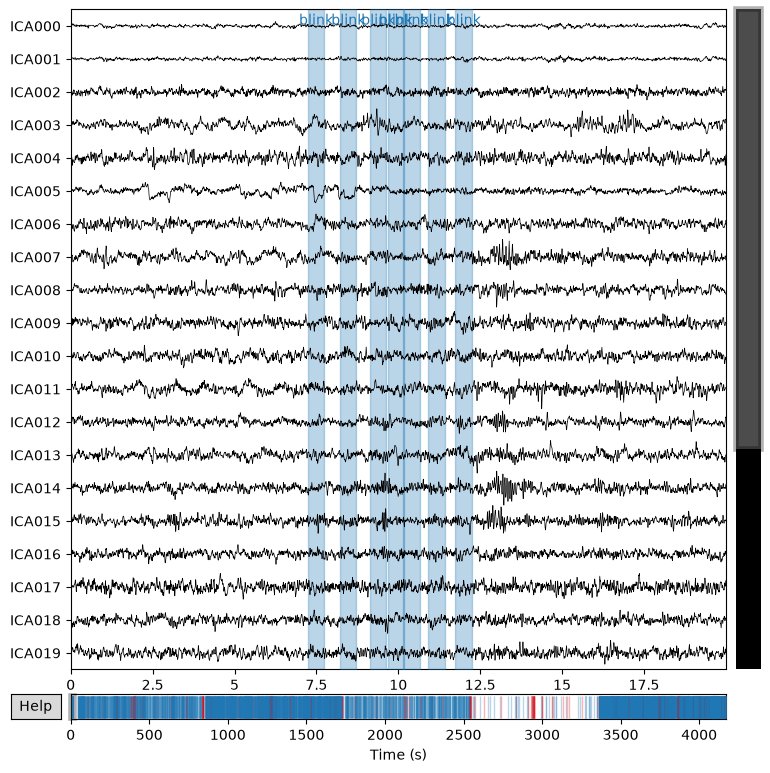

In [6]:
%matplotlib inline
# Plot time traces of all 30 ICA components
ica.plot_sources(raw_resmpl_all, title='ICA');

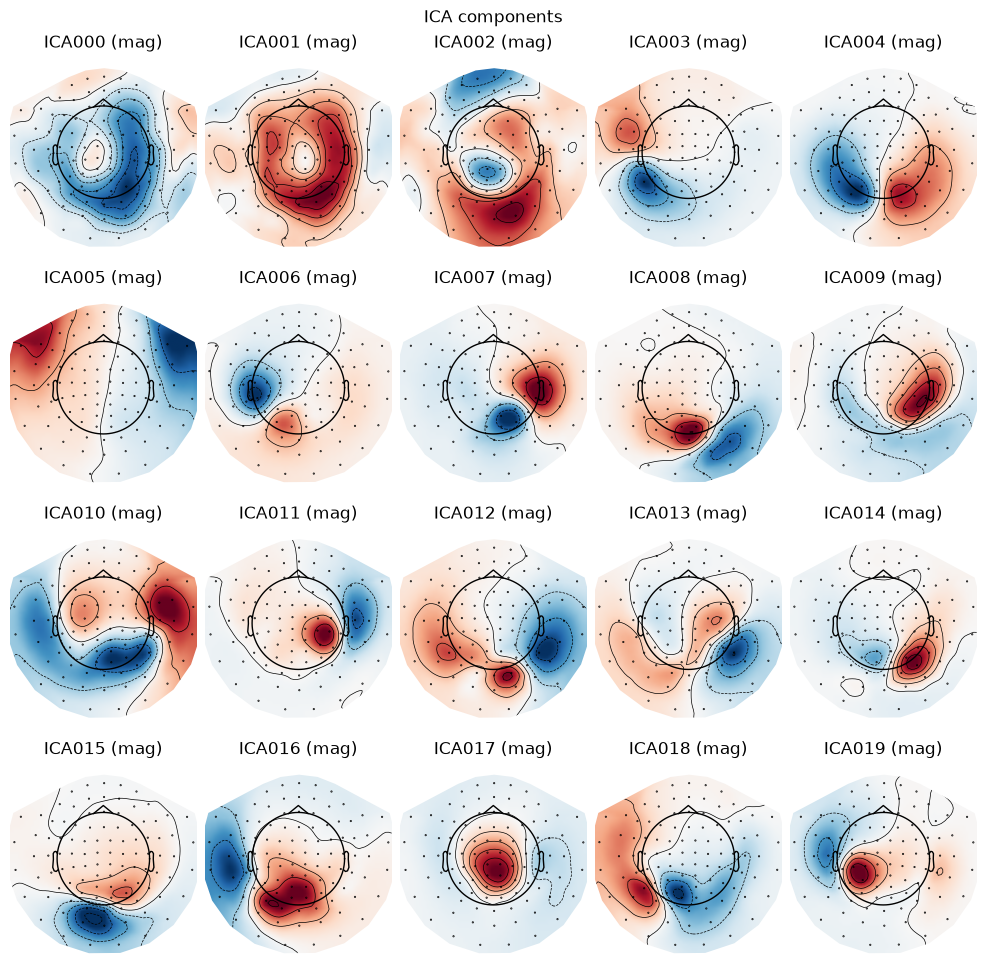

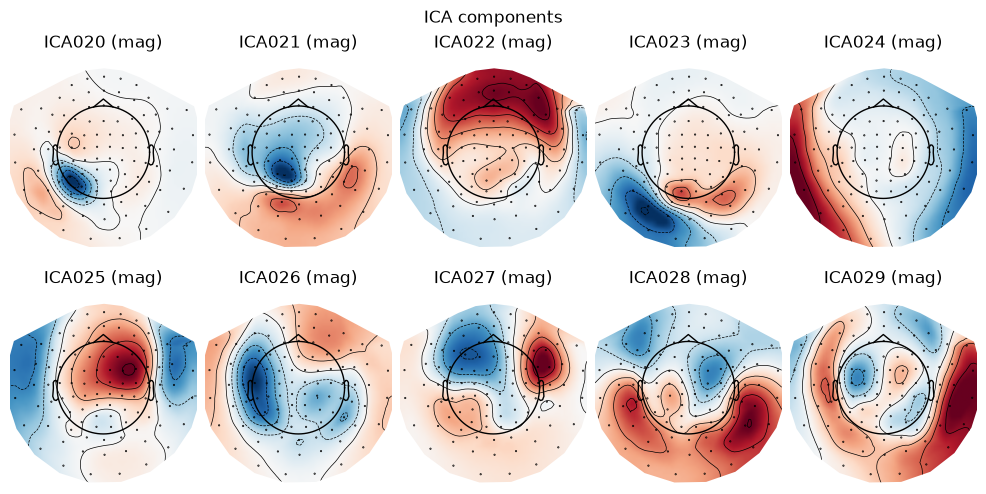

In [7]:
%matplotlib inline
# Plot spatial sensor topographies for all 30 components
ica.plot_components();

In [8]:
# --- SET COMPONENTS TO EXCLUDE ---
# Replace this list with the exact component indices you identified from the plots above!
# For example, if ICA000 is blinks and ICA003 is cardiac, set: ica.exclude = [0, 3]
ica.exclude = [1, 5]  # <--- UPDATE THIS based on your inspection of Cells 5 & 6

print(f"Components marked for rejection: {ica.exclude}")

# --- APPLY PROJECTIONS TO ALL 5 RUNS ---
for i, in_path in enumerate(input_files):
    out_path = ica_files[i]
    print(f"\nApplying ICA to Run {i+1:02d}: {os.path.basename(in_path)}")
    
    # Load un-downsampled data (with original annotations intact)
    raw_run = mne.io.read_raw_fif(in_path, preload=True, verbose=False)
    
    # Remove the excluded components
    ica.apply(raw_run)
    
    # Save cleaned file
    raw_run.save(out_path, overwrite=True)
    print(f"Saved: {os.path.basename(out_path)}")
    
    del raw_run
    gc.collect()

print("\nAll 5 runs successfully cleaned with ICA and saved to derivatives!")

Components marked for rejection: [1, 5]

Applying ICA to Run 01: sub-CA103_ses-1_task-dur_run-01_ann.fif


C:\Users\manju\AppData\Local\Temp\ipykernel_28312\2665123440.py:14: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ann.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw_run = mne.io.read_raw_fif(in_path, preload=True, verbose=False)


Applying ICA to Raw instance
    Transforming to ICA space (30 components)
    Zeroing out 2 ICA components
    Projecting back using 306 PCA components


C:\Users\manju\AppData\Local\Temp\ipykernel_28312\2665123440.py:20: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw_run.save(out_path, overwrite=True)


Writing C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ica.fif
Closing C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ica.fif
[done]
Saved: sub-CA103_ses-1_task-dur_run-01_ica.fif

Applying ICA to Run 02: sub-CA103_ses-1_task-dur_run-02_ann.fif


...

Closing C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-04_ica.fif
[done]
Saved: sub-CA103_ses-1_task-dur_run-04_ica.fif

Applying ICA to Run 05: sub-CA103_ses-1_task-dur_run-05_ann.fif


C:\Users\manju\AppData\Local\Temp\ipykernel_28312\2665123440.py:14: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ann.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw_run = mne.io.read_raw_fif(in_path, preload=True, verbose=False)


Applying ICA to Raw instance
    Transforming to ICA space (30 components)
    Zeroing out 2 ICA components
    Projecting back using 306 PCA components


C:\Users\manju\AppData\Local\Temp\ipykernel_28312\2665123440.py:20: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw_run.save(out_path, overwrite=True)


Writing C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ica.fif
Closing C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-05_ica.fif
[done]
Saved: sub-CA103_ses-1_task-dur_run-05_ica.fif

All 5 runs successfully cleaned with ICA and saved to derivatives!


In [9]:
# Frontal magnetometers and EOG channels for comparison
chs = ['MEG0311', 'MEG0121', 'MEG1211', 'MEG1411', 'EOG001']

# Load Run 1 before and after ICA for visual inspection
raw_before = mne.io.read_raw_fif(input_files[0], preload=True, verbose=False)
raw_after = mne.io.read_raw_fif(ica_files[0], preload=True, verbose=False)

chan_idxs = [raw_before.ch_names.index(ch) for ch in chs]

C:\Users\manju\AppData\Local\Temp\ipykernel_28312\3892508319.py:5: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ann.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw_before = mne.io.read_raw_fif(input_files[0], preload=True, verbose=False)
C:\Users\manju\AppData\Local\Temp\ipykernel_28312\3892508319.py:6: RuntimeWarning: This filename (C:\Users\manju\Desktop\Academia\26_iitroorkee_a\data\sub-CA103\ses-1\derivatives\sub-CA103_ses-1_task-dur_run-01_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  raw_after = mne.io.read_

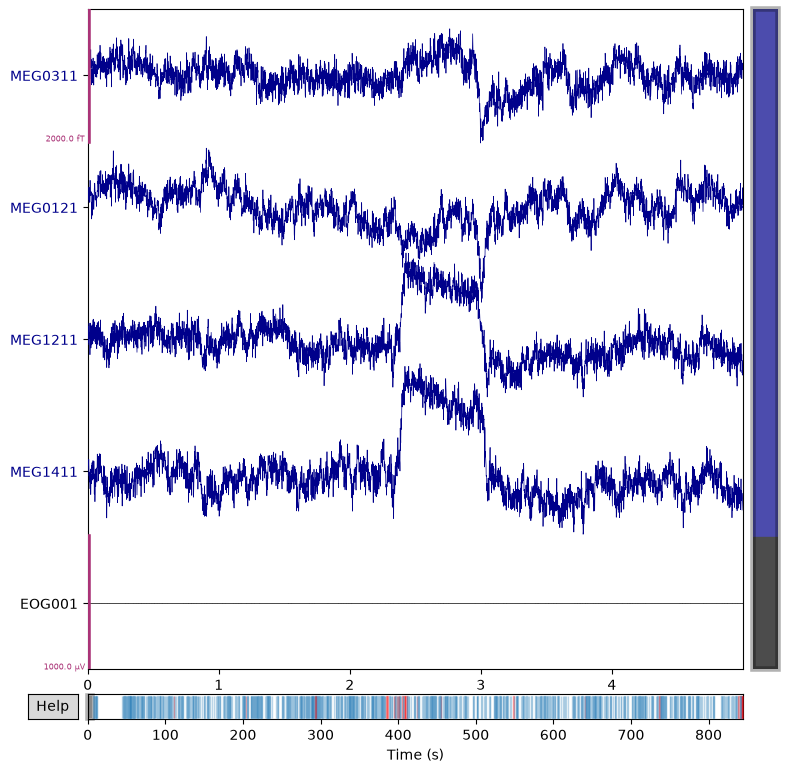

In [10]:
%matplotlib inline
# Raw traces BEFORE ICA
scl = dict(mag=1e-12, grad=40e-11, eog=500e-6)
raw_before.plot(order=chan_idxs, duration=5.0, scalings=scl, title="Before ICA");

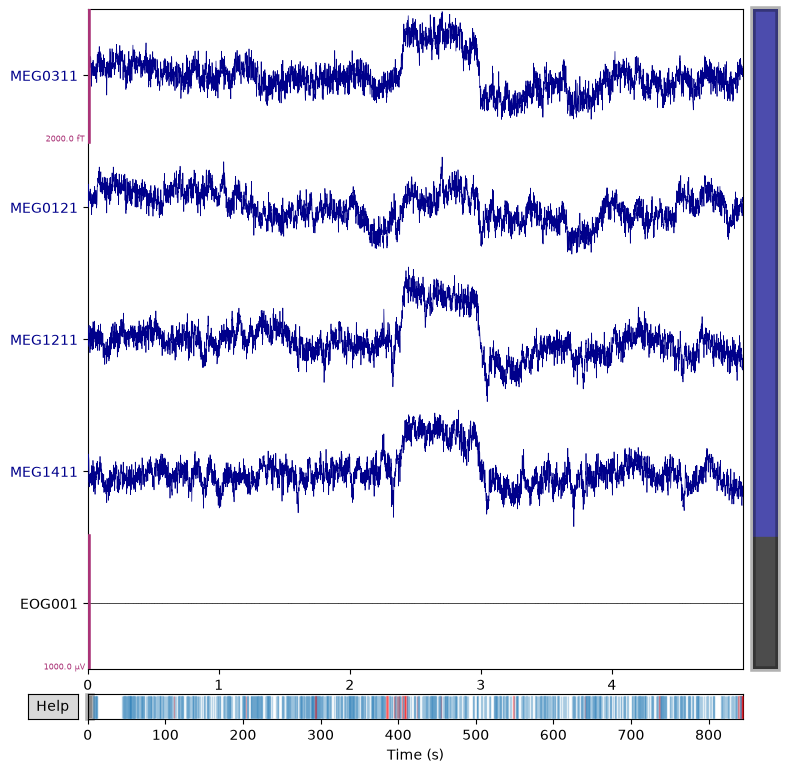

In [11]:
%matplotlib inline
# Cleaned traces AFTER ICA
raw_after.plot(order=chan_idxs, duration=5.0, scalings=scl, title="After ICA");